# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Load the dataset
The dataset is in the `dataset` folder next to this notebook.

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

# how many training questions the model gets right
pred = model(X)[0].argmax(1)
print("Training accuracy:", (pred == y).float().mean().item())

Training finished!
Training accuracy: 0.380952388048172


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

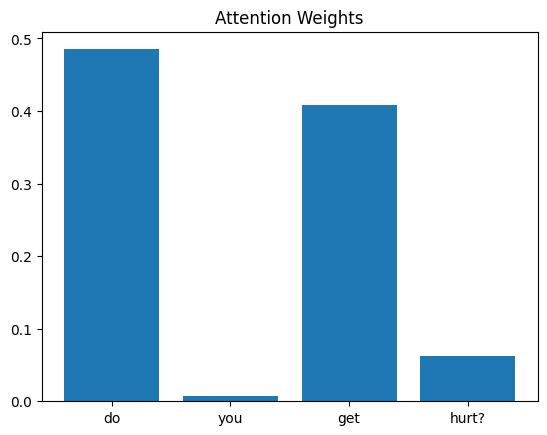

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

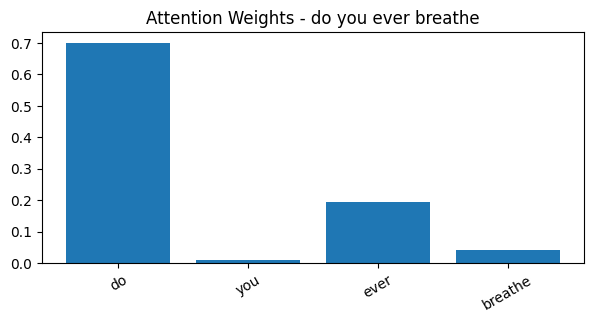

Question: do you ever breathe
Predicted answer_id: 0 | real answer_id: 0
Highest attention word: do -> 0.7



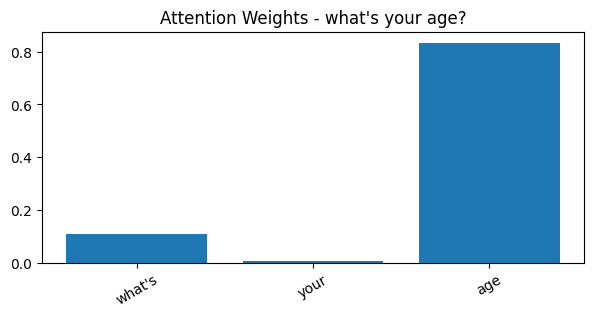

Question: what's your age?
Predicted answer_id: 10 | real answer_id: 1
Highest attention word: age -> 0.834



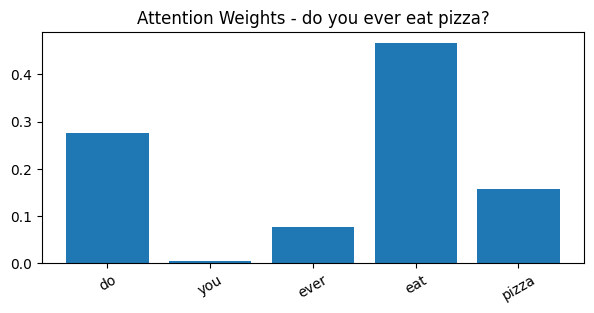

Question: do you ever eat pizza?
Predicted answer_id: 10 | real answer_id: 7
Highest attention word: eat -> 0.467



In [7]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

def show_attention(i):
    question = df["question"][i]
    # same words that the tokenizer used, so the bars match the weights
    words = text_to_word_sequence(question)
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    w = weights[0, :len(words)].tolist()
    plt.figure(figsize=(7, 3))
    plt.bar(words, w)
    plt.title(f"Attention Weights - {df['question'][i]}")
    plt.xticks(rotation=30)
    plt.show()
    top = words[w.index(max(w))]
    print("Question:", question)
    print("Predicted answer_id:", prediction.argmax().item(), "| real answer_id:", y[i].item())
    print("Highest attention word:", top, "->", round(max(w), 3))
    print()

# three different questions from the dataset
for i in [2, 20, 100]:
    show_attention(i)

**Answer (Task 1):**

I used the questions "do you ever breathe", "what's your age?" and "do you ever eat pizza?". The words with the highest attention were:
- "do" (0.70) in the first question
- "age" (0.83) in the second question
- "eat" (0.47) in the third question

In the second and third questions the highest word is an important word ("age" and "eat" are the main idea of the question). In the first question it is "do", which is not important, because the real important word is "breathe". The model still gave the right answer for it, but only because many questions of the same group start with "do you". Also, the model predicted the wrong answer for the second and third questions, so a high attention weight does not always mean the model understood the question. The training accuracy is only 0.38, so the attention weights are not very reliable.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

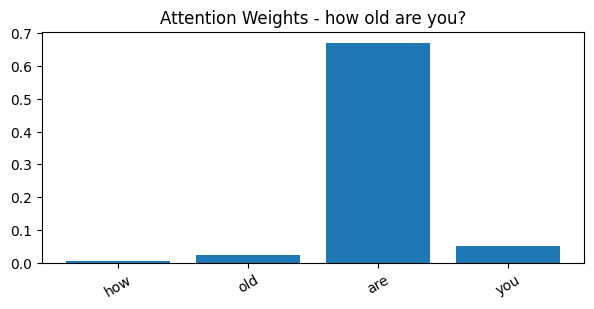

Question: how old are you?
Predicted answer_id: 3 | real answer_id: 1
Highest attention word: are -> 0.67



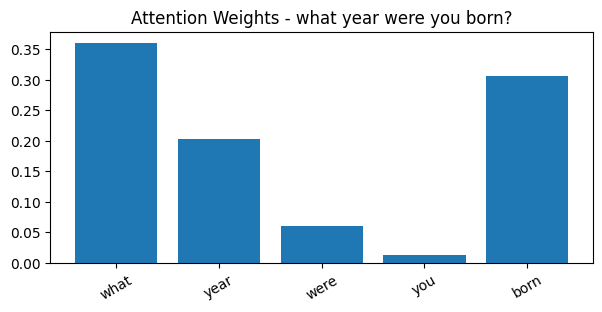

Question: what year were you born?
Predicted answer_id: 5 | real answer_id: 1
Highest attention word: what -> 0.36



In [8]:
# two questions with similar meaning but different wording (both ask about age)
for q in ["How old are you?", "What year were you born?"]:
    idx = df.index[df["question"] == q.lower()][0]
    show_attention(idx)

**Answer (Task 2):**

I used "how old are you?" and "what year were you born?". Both ask about age and both have the same answer_id (1). The model focused on different words: "are" (0.67) in the first one and "what" (0.36) in the second one, and the attention in the second question is spread more evenly over the words. The model also predicted two different (and wrong) answers (3 and 5).

So the model does not focus on the same words for questions with the same meaning. This suggests that attention does not understand meaning by itself. It only learns which words help to reduce the loss on the training data, so it depends on the exact words in the sentence and on how good the model is. With a small dataset (168 questions) and a simple RNN, similar questions with different wording get different attention.

## Observations

- The dataset has 168 questions in 12 answer groups (14 questions in each group).
- After 50 epochs the training accuracy is only 0.38, so the model is not trained well. One reason is that I trained on the whole dataset at once with a simple RNN and a small number of epochs, as in the lab.
- Attention gives each word a weight and the weights sum to 1. Sometimes the highest word is meaningful ("age", "eat") and sometimes it is not ("do", "are", "what").
- For similar questions the model used different words and gave different answers, so attention here is not a reliable explanation of the meaning.